# Epidemic Dynamics & Forecasting — ARIMA (COVID-19, India)

This notebook evaluates an ARIMA time-series model using India's OWID COVID-19 data.

**Standard project split**
- Training data: dataset start through **2021-09-30**
- Test / forecast period: **2021-10-01 through 2022-03-31**
- Target: `new_cases_smoothed`

The model is fitted only on the training period and generates a fixed-horizon forecast for the full test period. The test observations are not used to update the model or select its order.

## 1. Imports and configuration

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_PATH = "df_india.csv"
TARGET_COL = "new_cases_smoothed"

train_end_date = pd.Timestamp("2021-09-30")
end_date = pd.Timestamp("2022-03-31")

# Small grid search
p_values = range(0, 4)
d_values = [0, 1, 2]
q_values = range(0, 4)

## 2. Load and prepare India's data

In [4]:
df = pd.read_csv(DATA_PATH)

required_cols = {"date", TARGET_COL}
missing_cols = required_cols - set(df.columns)
if missing_cols:
    raise ValueError(f"Missing required columns in {DATA_PATH}: {sorted(missing_cols)}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")

# If the file contains multiple locations, retain India only.
if "location" in df.columns:
    df = df.loc[df["location"].eq("India")].copy()

df = df.loc[df["date"].notna() & (df["date"] <= end_date), ["date", TARGET_COL]]
df = df.sort_values("date").drop_duplicates(subset="date", keep="last")

# Make the daily series continuous. Interpolate gaps only within the available
# date range, then fill any edge gaps with the nearest observed value.
if df.empty:
    raise ValueError("No India observations found in the requested date range.")

daily_index = pd.date_range(df["date"].min(), end_date, freq="D")
y = df.set_index("date")[TARGET_COL].reindex(daily_index)
y.index.name = "date"
y = y.interpolate(method="time").ffill().bfill().clip(lower=0)
y.name = TARGET_COL

print(f"Data range: {y.index.min().date()} to {y.index.max().date()}")
print(f"Total daily observations: {len(y):,}")
display(y.head())
display(y.tail())

Data range: 2020-01-30 to 2022-03-31
Total daily observations: 792


date
2020-01-30    0.142857
2020-01-31    0.142857
2020-02-01    0.142857
2020-02-02    0.285714
2020-02-03    0.428571
Freq: D, Name: new_cases_smoothed, dtype: float64

date
2022-03-27    1658.8572
2022-03-28    1619.0000
2022-03-29    1573.0000
2022-03-30    1495.1428
2022-03-31    1393.2858
Freq: D, Name: new_cases_smoothed, dtype: float64

## 3. Create the standard chronological train/test split

Training observations: 610
Testing observations: 182
Training period: 2020-01-30 to 2021-09-30
Test period: 2021-10-01 to 2022-03-31


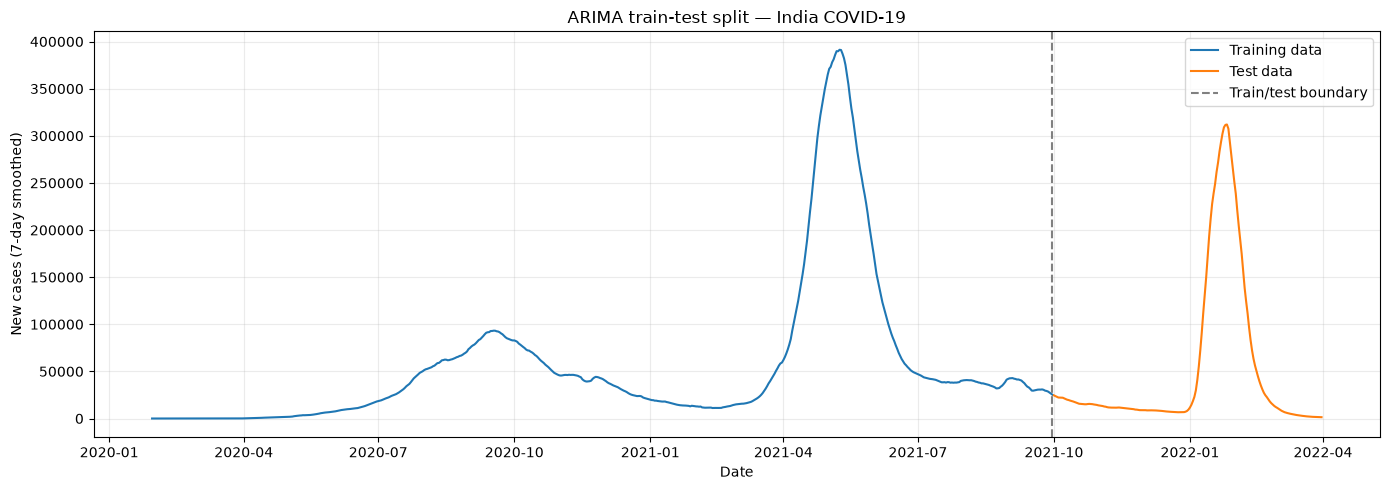

In [5]:
train = y.loc[:train_end_date].copy()
test = y.loc[train_end_date + pd.Timedelta(days=1):end_date].copy()

if train.empty or test.empty:
    raise ValueError("Train or test split is empty. Check the source data and date boundaries.")

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training period:", train.index.min().date(), "to", train.index.max().date())
print("Test period:", test.index.min().date(), "to", test.index.max().date())

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train, label="Training data")
ax.plot(test.index, test, label="Test data")
ax.axvline(train_end_date, linestyle="--", color="gray", label="Train/test boundary")
ax.set_title("ARIMA train-test split — India COVID-19")
ax.set_xlabel("Date")
ax.set_ylabel("New cases (7-day smoothed)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Stationarity diagnostics

The Augmented Dickey-Fuller (ADF) test has a null hypothesis that the series has a unit root. A small p-value provides evidence against that null. This is a diagnostic, not a complete decision rule by itself; inspect plots and differenced series too.

All diagnostics below use **training data only**.

C:\Users\FixTest\AppData\Local\Temp\ipykernel_27244\4083723785.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_original = adfuller(train.dropna(), autolag="AIC")


ADF statistic (original training series): -1.9733801413333043
ADF p-value: 0.2983655424527035


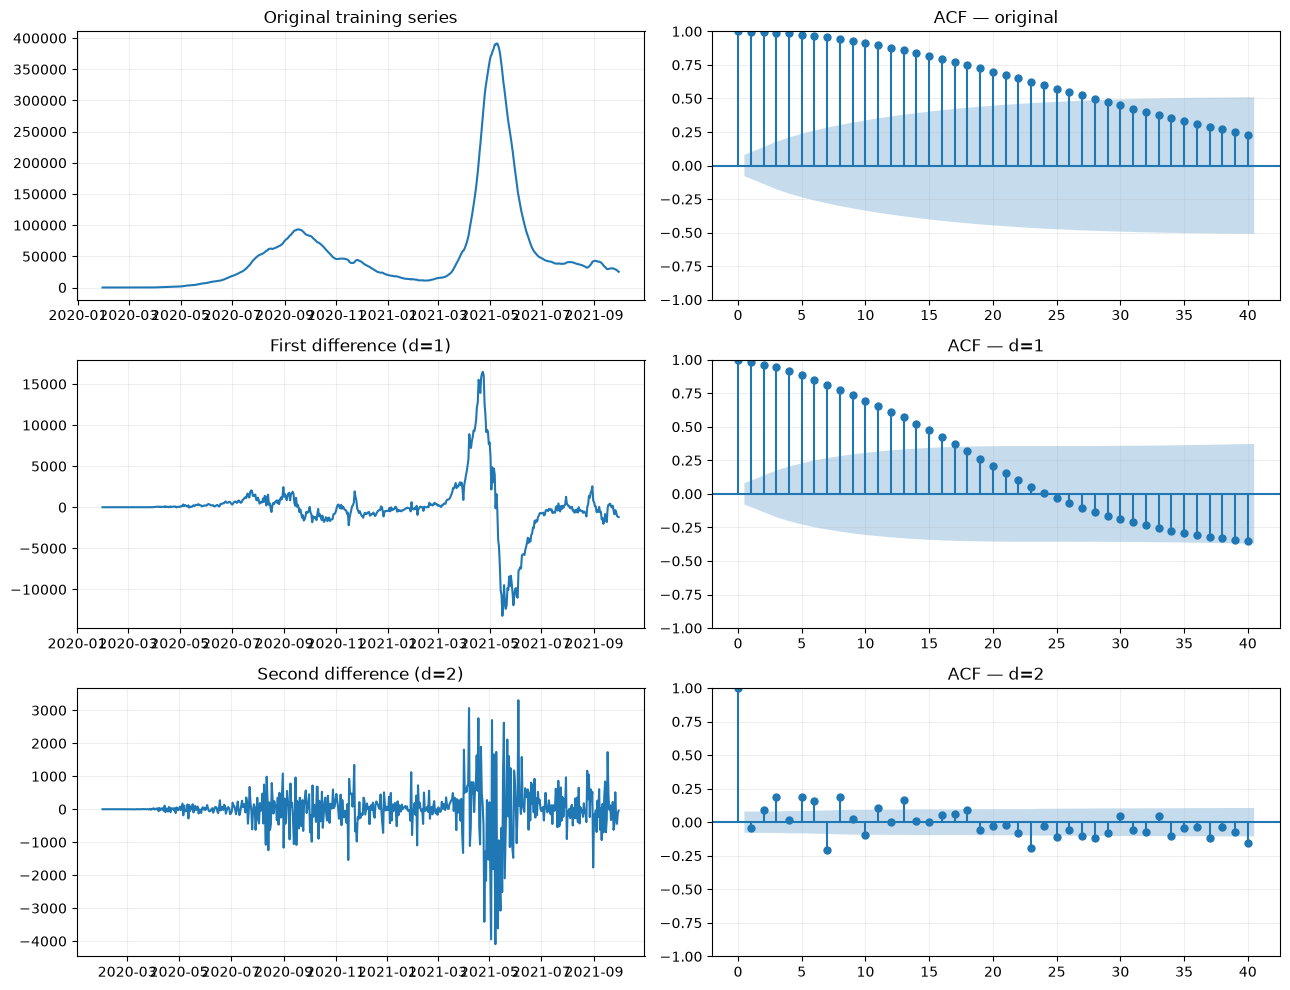

Original: ADF statistic=-1.9734, p-value=0.298366
First difference: ADF statistic=-5.4636, p-value=0.000002
Second difference: ADF statistic=-4.5311, p-value=0.000173


C:\Users\FixTest\AppData\Local\Temp\ipykernel_27244\4083723785.py:31: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag="AIC")
C:\Users\FixTest\AppData\Local\Temp\ipykernel_27244\4083723785.py:31: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag="AIC")
C:\Users\FixTest\AppData\Local\Temp\ipyker

In [6]:
adf_original = adfuller(train.dropna(), autolag="AIC")
print("ADF statistic (original training series):", adf_original[0])
print("ADF p-value:", adf_original[1])

train_diff_1 = train.diff().dropna()
train_diff_2 = train.diff().diff().dropna()

fig, axes = plt.subplots(3, 2, figsize=(13, 10))

axes[0, 0].plot(train)
axes[0, 0].set_title("Original training series")
plot_acf(train, lags=40, ax=axes[0, 1])
axes[0, 1].set_title("ACF — original")

axes[1, 0].plot(train_diff_1)
axes[1, 0].set_title("First difference (d=1)")
plot_acf(train_diff_1, lags=40, ax=axes[1, 1])
axes[1, 1].set_title("ACF — d=1")

axes[2, 0].plot(train_diff_2)
axes[2, 0].set_title("Second difference (d=2)")
plot_acf(train_diff_2, lags=40, ax=axes[2, 1])
axes[2, 1].set_title("ACF — d=2")

for ax in axes.flat:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

for label, series in [("Original", train), ("First difference", train_diff_1), ("Second difference", train_diff_2)]:
    result = adfuller(series.dropna(), autolag="AIC")
    print(f"{label}: ADF statistic={result[0]:.4f}, p-value={result[1]:.6f}")

## 5. Inspect PACF and choose candidate ARIMA orders

The order search below uses AIC on the training data only. It tests a modest grid of `(p, d, q)` candidates. AIC is a model-selection heuristic; it does not guarantee the best out-of-sample forecast. We keep the test period untouched until final evaluation.

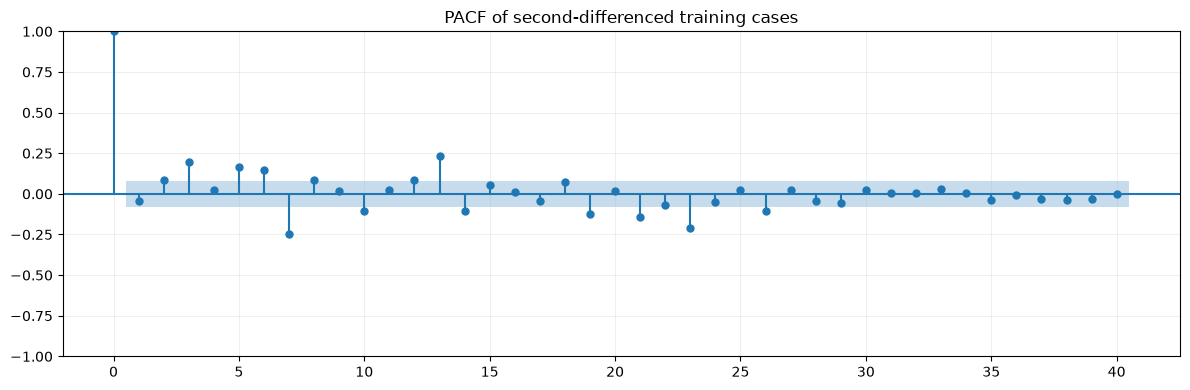

In [7]:
pacf_lags = min(40, max(1, len(train_diff_2) // 2 - 1))
fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(train_diff_2, lags=pacf_lags, ax=ax, method="ywm")
ax.set_title("PACF of second-differenced training cases")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [8]:
results = []

for p in p_values:
    for d in d_values:
        for q in q_values:
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    fitted = ARIMA(
                        train,
                        order=(p, d, q),
                        enforce_stationarity=False,
                        enforce_invertibility=False
                    ).fit()

                results.append({
                    "p": p,
                    "d": d,
                    "q": q,
                    "AIC": fitted.aic,
                    "BIC": fitted.bic
                })
            except Exception as exc:
                # Keep the grid search running if an individual order fails.
                print(f"ARIMA({p},{d},{q}) failed: {exc}")

arima_results = pd.DataFrame(results)
if arima_results.empty:
    raise RuntimeError("No ARIMA candidate models fitted successfully.")

arima_results = arima_results.sort_values("AIC").reset_index(drop=True)
display(arima_results.head(10))

,p,d,q,AIC,BIC
0,3,2,3,9510.833339,9541.658359
1,2,2,3,9534.059194,9560.480639
2,1,2,3,9535.296461,9557.314332
3,2,1,3,9537.884962,9564.316333
4,3,1,3,9539.874991,9570.711590
5,2,2,2,9546.661510,9568.687652
6,2,1,2,9549.813193,9571.847593
7,0,2,3,9550.957832,9568.572129
8,3,1,1,9550.976262,9573.010661
9,3,2,1,9552.714335,9574.740478


In [10]:
best_order = tuple(int(arima_results.loc[0, col]) for col in ["p", "d", "q"])
print("Selected ARIMA order (lowest training AIC):", best_order)

Selected ARIMA order (lowest training AIC): (3, 2, 3)


## 6. Fit the selected ARIMA model on training data

In [11]:
with warnings.catch_warnings():
    warnings.simplefilter("default")
    arima_fitted = ARIMA(
        train,
        order=best_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit()

print(arima_fitted.summary())

                               SARIMAX Results                                
Dep. Variable:     new_cases_smoothed   No. Observations:                  610
Model:                 ARIMA(3, 2, 3)   Log Likelihood               -4748.417
Date:                Wed, 21 Oct 2026   AIC                           9510.833
Time:                        02:24:44   BIC                           9541.658
Sample:                    01-30-2020   HQIC                          9522.829
                         - 09-30-2021                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0182      0.051      0.356      0.722      -0.082       0.119
ar.L2         -0.0787      0.031     -2.577      0.010      -0.139      -0.019
ar.L3          0.7740      0.037     20.925      0.0

## 7. Forecast the full test period

This is a **fixed-origin multi-step forecast**: the model is fitted through September 30, 2021, and then predicts October 1, 2021–March 31, 2022 without incorporating test observations. This makes the evaluation comparable to a forecast issued at the training cutoff.

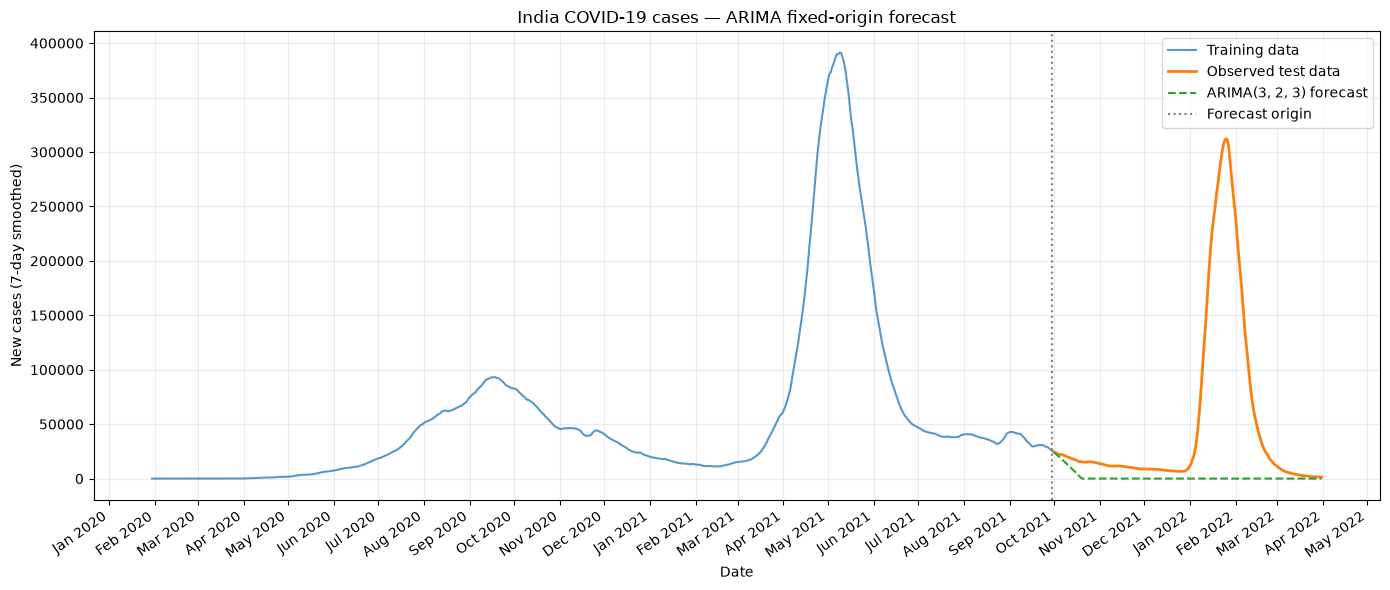

In [12]:
forecast_values = arima_fitted.forecast(steps=len(test))
forecast = pd.Series(
    np.asarray(forecast_values),
    index=test.index,
    name="arima_predicted_cases"
).clip(lower=0)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(train.index, train, label="Training data", alpha=0.75)
ax.plot(test.index, test, label="Observed test data", linewidth=2)
ax.plot(forecast.index, forecast, label=f"ARIMA{best_order} forecast", linestyle="--")
ax.axvline(train_end_date, linestyle=":", color="gray", label="Forecast origin")
ax.set_title("India COVID-19 cases — ARIMA fixed-origin forecast")
ax.set_xlabel("Date")
ax.set_ylabel("New cases (7-day smoothed)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Evaluation on the standard test period

In [13]:
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))
r2 = r2_score(test, forecast)

print(f"Test MAE:  {mae:,.2f}")
print(f"Test RMSE: {rmse:,.2f}")
print(f"Test R²:   {r2:.4f}")

Test MAE:  50,012.00
Test RMSE: 98,731.12
Test R²:   -0.3643


In [14]:
arima_predictions = pd.DataFrame({
    "date": test.index,
    "actual_cases": test.to_numpy(),
    "arima_predicted_cases": forecast.to_numpy()
})
display(arima_predictions.head())

,date,actual_cases,arima_predicted_cases
0,2021-10-01,24557.715,23991.471848
1,2021-10-02,23806.000,23093.344082
2,2021-10-03,23022.572,21845.389593
3,2021-10-04,22273.715,20539.988154
4,2021-10-05,22209.572,19518.903040


## 9. Residual analysis

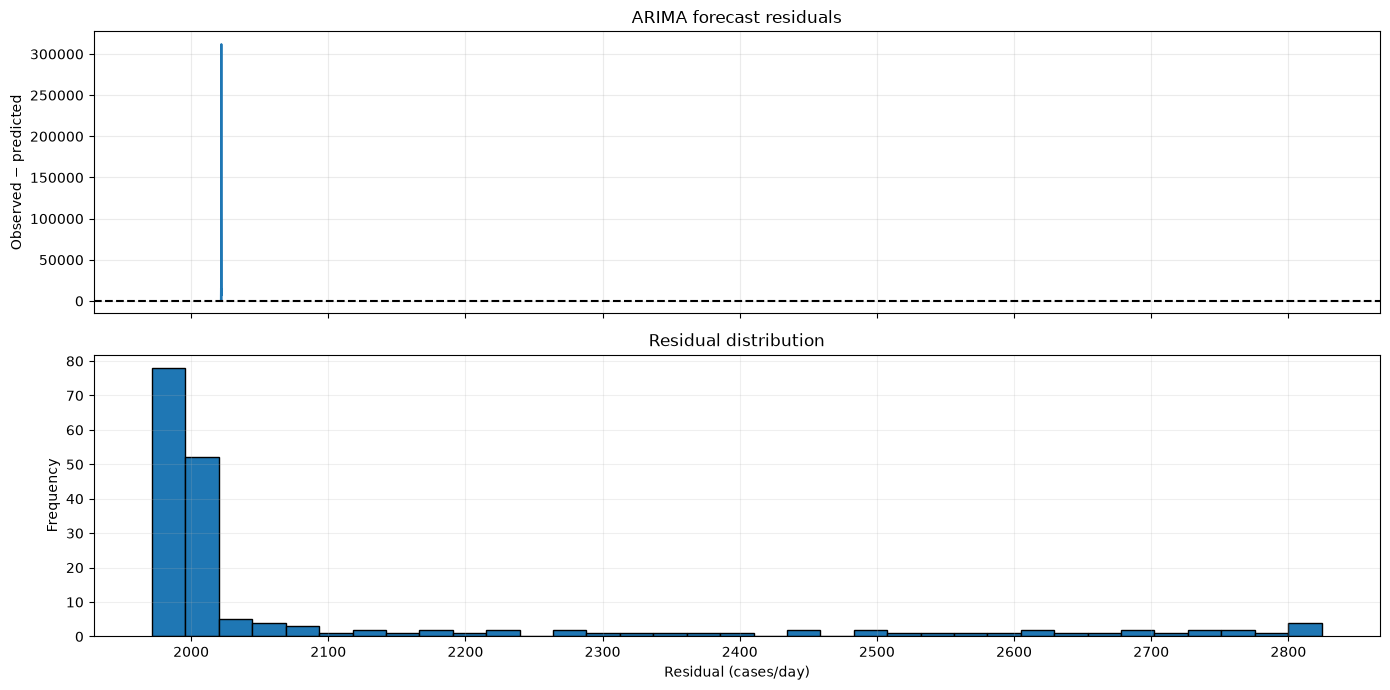

In [15]:
residuals = test - forecast

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(residuals.index, residuals)
axes[0].axhline(0, linestyle="--", color="black")
axes[0].set_title("ARIMA forecast residuals")
axes[0].set_ylabel("Observed − predicted")
axes[0].grid(alpha=0.25)

axes[1].hist(residuals.dropna(), bins=35, edgecolor="black")
axes[1].set_title("Residual distribution")
axes[1].set_xlabel("Residual (cases/day)")
axes[1].set_ylabel("Frequency")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

## 10. Save predictions and metrics

In [16]:
arima_predictions.to_csv("arima_predictions_standard_split.csv", index=False)

model_results = pd.DataFrame({
    "Model": ["ARIMA"],
    "Order": [str(best_order)],
    "Train_End_Date": [train_end_date.date().isoformat()],
    "Test_Start_Date": [test.index.min().date().isoformat()],
    "Test_End_Date": [test.index.max().date().isoformat()],
    "MAE": [mae],
    "RMSE": [rmse],
    "R2": [r2]
})
display(model_results)
model_results.to_csv("arima_metrics_standard_split.csv", index=False)

print("Saved arima_predictions_standard_split.csv")
print("Saved arima_metrics_standard_split.csv")

,Model,Order,Train_End_Date,Test_Start_Date,Test_End_Date,MAE,RMSE,R2
0,ARIMA,"(3, 2, 3)",2021-09-30,2021-10-01,2022-03-31,50011.996531,98731.12073,-0.364344


Saved arima_predictions_standard_split.csv
Saved arima_metrics_standard_split.csv


## Interpretation and limitations

- This notebook uses `new_cases_smoothed` as the target and the standard project dates.
- The ARIMA order is selected by AIC on training data only; model order selection should ideally also be checked with a chronological validation set.
- The forecast is fixed-origin and multi-step. ARIMA does not get updated with observed test-period cases.
- Large forecast errors during a new epidemic wave may reflect structural changes that cannot be inferred from past case counts alone.
- For a fair comparison, SIR, XGBoost, and LSTM results must use the same target, test dates, and clearly stated forecasting strategy. In particular, rolling one-step-ahead LSTM predictions are not directly equivalent to this fixed-origin ARIMA forecast.
- OWID data may be revised, so results can change when the source CSV changes.